<a href="https://colab.research.google.com/github/Esraa-M-Dev/Computer-Vision-Tasks/blob/main/KMeans_CV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# K-Means Clustering for Image Segmentation

## Computer Vision Project

### Project Description
This project implements the K-Means Clustering
algorithm from scratch using Python.

The algorithm is used for Image Segmentation
by grouping similar pixel colors into clusters.

### Libraries
- NumPy
- OpenCV
- Matplotlib


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [3]:
def kmeans(data, k, max_iterations=100):

    np.random.seed(42)

    random_indices = np.random.choice(
        len(data), k, replace=False
    )

    centroids = data[random_indices]

    for iteration in range(max_iterations):

        distances = np.linalg.norm(
            data[:, np.newaxis] - centroids,
            axis=2
        )

        labels = np.argmin(distances, axis=1)

        new_centroids = np.zeros((k, data.shape[1]))

        for i in range(k):

            cluster_points = data[labels == i]

            if len(cluster_points) > 0:
                new_centroids[i] = np.mean(
                    cluster_points, axis=0
                )
            else:
                new_centroids[i] = centroids[i]

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return labels, centroids

Saving download.jpeg to download.jpeg


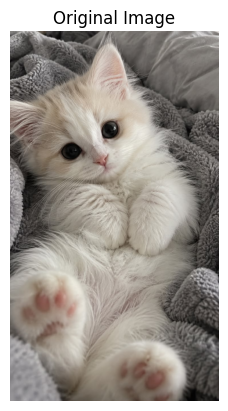

In [5]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = cv2.imread(image_path)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [6]:
pixels = image.reshape((-1, 3))

pixels = np.float32(pixels)

k = 3

labels, centroids = kmeans(pixels, k)

segmented_pixels = centroids[labels]

segmented_image = segmented_pixels.reshape(image.shape)

segmented_image = np.uint8(segmented_image)

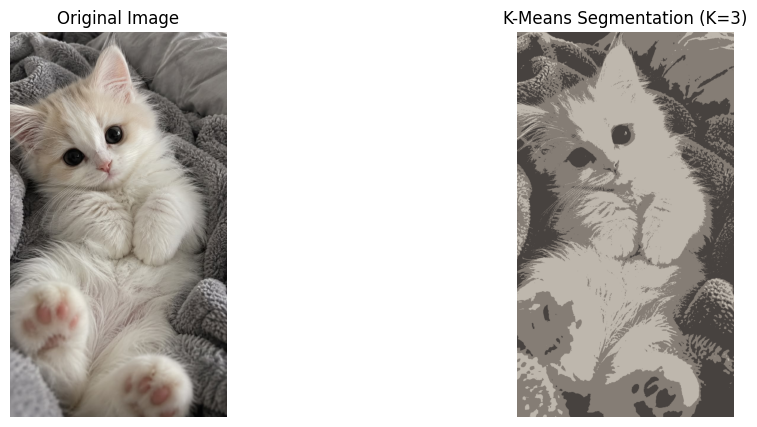

In [7]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented_image)
plt.title(f"K-Means Segmentation (K={k})")
plt.axis("off")

plt.show()

In [8]:
cv2.imwrite(
    "segmented.jpg",
    cv2.cvtColor(segmented_image, cv2.COLOR_RGB2BGR)
)

files.download("segmented.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>